# AIM: Pretraining GPT-2 Model on Unlabeled Data (20M Params, 100M Tokens, HF Auto-Batch Scaling & W&B Tracking)

# DOB: 18-11-2026

# Author: Shalu Singh


### Q.1) What Are the Three Main Stages of Building and Deploying an LLM?

**Answer:**

Building and training a modern large language model (LLM) is structured into three distinct developmental stages:

1. **Stage 1: Building the Architecture & Data Pipeline:**
   - **Data Preparation & Tokenization:** Gathering raw text corpora, converting character text into discrete token IDs using Byte-Pair Encoding (BPE with `tiktoken`), and formatting sequences with an efficient sliding-window data loader to yield input-target token batches.
   - **Attention Mechanism:** Designing causal multi-head self-attention layers so each token dynamically weighs context from preceding tokens while masking future tokens.
   - **Transformer Architecture:** Assembling the complete GPT model with Layer Normalization, GELU activations, FeedForward networks, residual shortcut connections, and positional embeddings.

2. **Stage 2: Pretraining on Unlabeled Data (Foundation Model):**
   - **Next-Token Prediction Objective:** Self-supervised training where the network learns general language patterns by predicting the next token across large unlabeled corpora.
   - **Loss Formulation & Training Loop:** Evaluating model loss with Cross-Entropy Loss, computing Perplexity, and optimizing parameters using the AdamW optimizer.
   - **Loss Curve Analysis & Overfitting:** Tracking training and validation losses across epochs, diagnosing memorization on small datasets vs generalization on large web corpora, and implementing checkpointing (`torch.save` / `torch.load`).
   - **Decoding Strategies:** Replacing greedy decoding with temperature scaling and top-$k$ sampling to generate original, diverse text.

3. **Stage 3: Fine-Tuning for Downstream Tasks:**
   - **Classification Fine-Tuning:** Adapting the pretrained foundation model for specific tasks such as sentiment analysis or spam filtering.
   - **Instruction Fine-Tuning:** Training on prompt-response instruction datasets to build interactive personal assistants (e.g., ChatGPT).

---
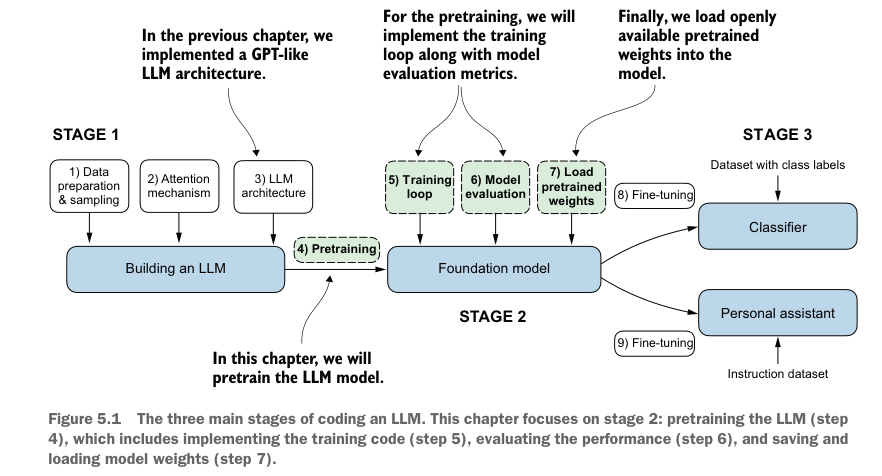
---


### Q.2) What Is Pretraining on Unlabeled Data and Why Is It Called Self-Supervised Learning?

**Answer:**

1. **Abundance of Unlabeled Text:** Supervised deep learning requires millions of human-annotated labels, which is prohibitively slow and expensive. In contrast, vast quantities of raw text (books, articles, websites, repositories) are freely accessible.
2. **Self-Supervised Label Creation:** Pretraining formulates a supervised learning task *directly out of unlabeled text* by shifting the text sequence forward by one position. For an input sequence $[x_1, x_2, \dots, x_t]$, the target sequence is naturally $[x_2, x_3, \dots, x_{t+1}]$. Thus, the raw text provides both the input and the ground-truth supervision signal without human annotation.
3. **Foundation Representation Learning:** By learning to predict the next token across diverse contexts, the model learns grammar, syntax, world knowledge, and logical dependencies, producing a versatile **Foundation Model**.

---
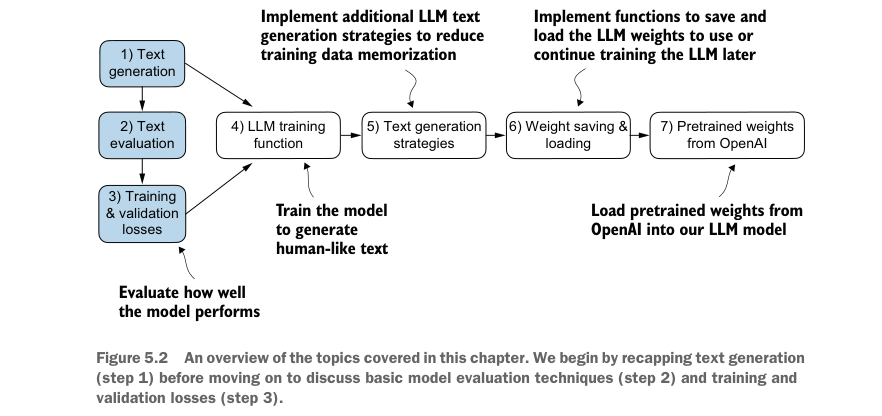
---


In [25]:
# ==============================================================
# 1. Imports and Environment Setup
# ==============================================================
import os
import urllib.request
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
try:
    import tiktoken
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "tiktoken"])
    import tiktoken
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tqdm.auto import tqdm
import gc

# Import Hugging Face Accelerate for automated batch scaling
try:
    from accelerate.utils import find_executable_batch_size
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "accelerate"])
    from accelerate.utils import find_executable_batch_size

# Import Weights & Biases for experiment tracking
try:
    import wandb
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "wandb"])
    import wandb

# Set random seed for reproducibility
torch.manual_seed(123)

# Multi-GPU Detection (e.g. 2x T4 on Kaggle)
num_gpus = torch.cuda.device_count()
device = torch.device("cuda:0" if num_gpus > 0 else "cpu")

print(f"PyTorch Version: {torch.__version__}")
print(f"Primary Device:  {device}")
print(f"Total GPUs:      {num_gpus}")
for i in range(num_gpus):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} | VRAM: {props.total_memory / (1024**3):.1f} GB")


PyTorch Version: 2.11.0+cu130
Primary Device:  cuda:0
Total GPUs:      2
  GPU 0: Tesla T4 | VRAM: 14.6 GB
  GPU 1: Tesla T4 | VRAM: 14.6 GB


## Foundational Building Blocks: GPT-2 Architecture (From Ch-3)

To ensure this notebook is **100% self-contained and directly executable in Kaggle** without external repository imports, we consolidate the complete GPT-2 neural network modules (`LayerNorm`, `GELU`, `FeedForward`, `MultiheadAttention`, `TransformerBlock`, `GPTModel`, and `generate_text_simple`).


In [26]:
# ==============================================================
# 2. GPT-2 Architecture Configuration (~20 Million Parameters)
# ==============================================================

# Calibrated for ~20M parameters for fast pretraining on 100M tokens
GPT2_CONFIG = {
    "vocab_size": 50257,    # Vocabulary size (BPE)
    "context_length": 1024,  # Context length
    "emb_dim": 512,         # Embedding dimension (scales total parameters to ~20M)
    "n_heads": 16,           # Number of attention heads (head_dim = 168 // 6 = 28)
    "n_layers": 6,         # Number of transformer blocks
    "drop_rate": 0.3,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias setting
}


In [44]:
user_prompt = """Q: What is the boiling point of water in Celsius?
A: 100

Q: What is the largest planet in our solar system?
A: Jupiter

Q: How many continents are there on Earth?
A: ?

Q: What is 2 + 2 * 3?
A:"""

In [45]:
# ==============================================================
# 3. GPT-2 Model Architecture Classes (from Ch-3)
# ==============================================================

class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1.0 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / math.pi)) * (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layer = nn.Sequential(
            nn.Linear(cfg["emb_dim"], cfg["emb_dim"] * 4),
            GELU(),
            nn.Linear(cfg["emb_dim"] * 4, cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layer(x)


class MultiheadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_len, num_heads, dropout, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_len, context_len), diagonal=1))
        self.out_proj = nn.Linear(d_out, d_out)

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        query = self.W_query(x)
        key = self.W_key(x)
        value = self.W_value(x)

        # Reshape to (b, num_heads, num_tokens, head_dim)
        query = query.reshape(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        key = key.reshape(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        value = value.reshape(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        att_score = query @ key.transpose(2, 3)
        att_score = att_score.masked_fill_(self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)

        att_weight = torch.softmax(att_score / (self.head_dim ** 0.5), dim=-1)
        att_weight = self.dropout(att_weight)

        context_vec = att_weight @ value
        context_vec = context_vec.transpose(1, 2).reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        return context_vec


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.att = MultiheadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_len=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg.get("qkv_bias", False)
        )
        self.dropout = nn.Dropout(cfg["drop_rate"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.ff = FeedForward(cfg)

    def forward(self, x):
        # Pre-LayerNorm with residual connections
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.dropout(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.dropout(x)
        x = x + shortcut
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.dropout_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, ip_idx):
        batch_size, seq_len = ip_idx.shape
        tok_embds = self.tok_emb(ip_idx)
        pos_embds = self.pos_emb(torch.arange(seq_len, device=ip_idx.device))
        x = tok_embds + pos_embds
        x = self.dropout_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


In [46]:
# ==============================================================
# 4. Text Generation Utility & Model Parameter Counter
# ==============================================================

def generate_text_simple(model, idx, max_new_tokens, context_size):
    """
    Greedy text generation: iteratively predicts one token at a time
    using argmax over the predicted next-token probability distribution.
    """
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]  # Crop context if length exceeds context_size
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]  # Extract logits of the very last position
        probas = torch.softmax(logits, dim=-1)
        next_idx = torch.argmax(probas, dim=-1, keepdim=True)
        idx = torch.cat((idx, next_idx), dim=1)
    return idx


def print_model_parameters(model):
    """
    Takes a PyTorch model and prints total parameters in Billions (B) and Millions (M).
    """
    raw_model = model.module if hasattr(model, "module") else model
    total_params = sum(p.numel() for p in raw_model.parameters())
    trainable_params = sum(p.numel() for p in raw_model.parameters() if p.requires_grad)
    
    print(f"Total Parameters:     {total_params / 1e9:.4f} Billion  ({total_params / 1e6:.2f} Million | {total_params:,} params)")
    print(f"Trainable Parameters: {trainable_params / 1e9:.4f} Billion  ({trainable_params / 1e6:.2f} Million | {trainable_params:,} params)")
    return total_params


# 5.1 Evaluating Generative Text Models

Before training our model, we must establish rigorous, quantitative ways to evaluate its generation performance:
1. Converting text to token IDs and back.
2. Observing an untrained model's output.
3. Formulating the next-token prediction loss from scratch.
4. Calculating Cross-Entropy Loss and Perplexity.


### Q.3) How Does an Untrained GPT-2 Model Generate Text, and Why Is Numerical Evaluation Essential?

**Answer:**

1. **The Three-Step Generation Flow:**
   - **Step 1 (Encoding):** The tokenizer converts input prompt text into a tensor of token IDs.
   - **Step 2 (Forward Pass):** The GPT model processes token IDs through token and position embeddings, 12 Transformer blocks, and a final linear projection layer to output an unscaled **logit vector of size 50,257** for every sequence position.
   - **Step 3 (Decoding):** Logits are mapped to probabilities via Softmax, the token ID with the highest probability is selected (`argmax`), and the tokenizer decodes the predicted token ID back into human-readable text.
2. **Why Untrained Models Output Incoherent Text:**
   - An initialized model has randomly assigned weights. Its output probability distribution is virtually uniform across the 50,257 tokens, yielding nonsensical random words and symbols.
3. **Why Numerical Evaluation Is Required:**
   - Visual inspection of generated sentences is subjective, qualitative, and impossible to automate across millions of optimization steps. We need a mathematical scalar value (**loss**) that quantifies prediction error and provides gradients to adjust parameters via backpropagation.

---
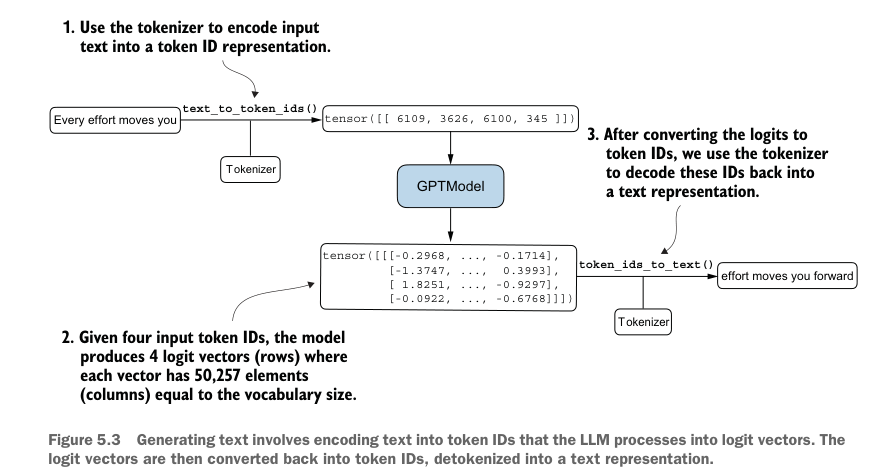
---


In [47]:
# ==============================================================
# 5.1.1 Testing Untrained GPT-2 Model Text Generation
# ==============================================================

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # Add batch dimension [1, num_tokens]
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)  # Remove batch dimension
    return tokenizer.decode(flat.tolist())

# Initialize model with random weights
torch.manual_seed(123)
model = GPTModel(GPT2_CONFIG)
model.eval()

# Print model parameter count
print_model_parameters(model)

start_context = user_prompt
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT2_CONFIG["context_length"]
)

print("\nPrompt:", start_context)
print("Output text from Untrained Model:\n", token_ids_to_text(token_ids, tokenizer))


Total Parameters:     0.0709 Billion  (70.89 Million | 70,893,568 params)
Trainable Parameters: 0.0709 Billion  (70.89 Million | 70,893,568 params)

Prompt: Q: What is the boiling point of water in Celsius?
A: 100

Q: What is the largest planet in our solar system?
A: Jupiter

Q: How many continents are there on Earth?
A: ?

Q: What is 2 + 2 * 3?
A:
Output text from Untrained Model:
 Q: What is the boiling point of water in Celsius?
A: 100

Q: What is the largest planet in our solar system?
A: Jupiter

Q: How many continents are there on Earth?
A: ?

Q: What is 2 + 2 * 3?
A: OFberman LEGyk……………………NoticeTabps psychology024


### Q.4) How Does the Next-Token Prediction Objective Work, and How Are Target Tokens Prepared?

**Answer:**

1. **Autoregressive Modeling:**
   - For an input sequence with $N$ tokens $[x_1, x_2, \dots, x_N]$, the network's goal at each index $t$ is to predict the immediate next token $x_{t+1}$.
2. **Input and Target Alignment (Shifted by 1):**
   - The target tensor is simply the input tensor shifted forward by one position:
     $$\\text{Inputs: } [x_1, x_2, \\dots, x_{N-1}]$$
     $$\\text{Targets: } [x_2, x_3, \\dots, x_N]$$
3. **Probability Vector across Vocabulary:**
   - For each input token, the model computes a 50,257-dimensional probability vector. In an untrained model, probability values are randomly distributed around $\\frac{1}{50257} \\approx 0.00002$.
   - **Training Objective:** Adjust model weights so that the probability corresponding to the *correct target token ID* is maximized (approaching $1.0$).

---
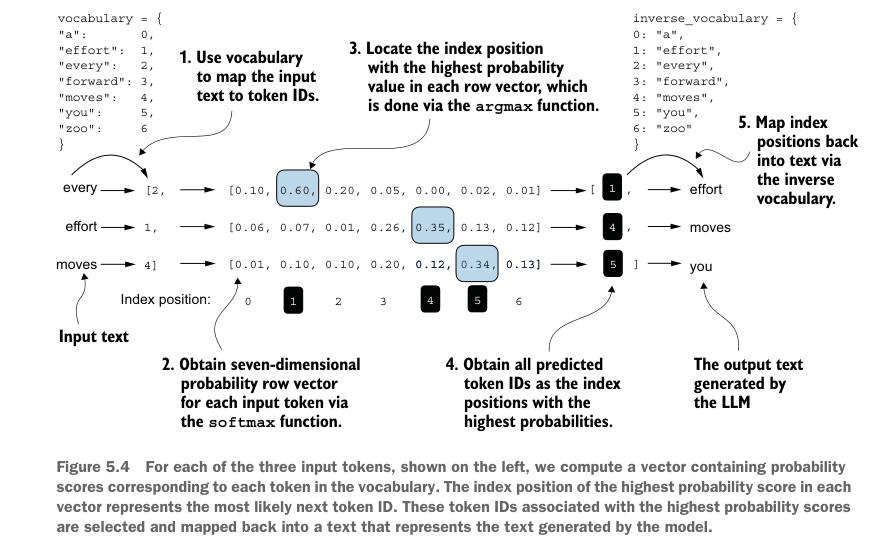
---
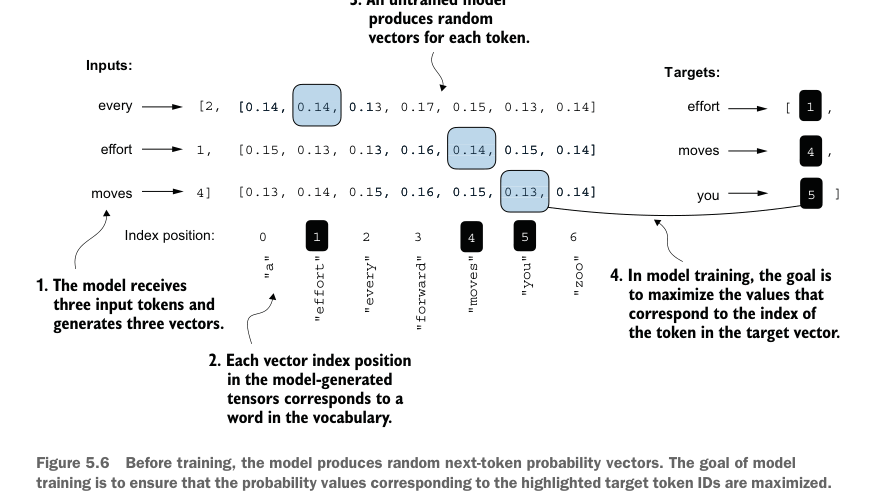
---


In [48]:
# ==============================================================
# Demonstrating Next-Token Probabilities with Two Sample Batches
# ==============================================================

# Input batches (Batch size 2, Sequence length 3)
inputs = torch.tensor([
    [16833, 3626, 6100],  # "every effort moves"
    [40, 1107, 588]       # "I really like"
])

# Shifted target tokens
targets = torch.tensor([
    [3626, 6100, 345],    # " effort moves you"
    [1107, 588, 11311]    # " really like chocolate"
])

# Forward pass without gradients
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1)
print("Logits shape: ", logits.shape)   # [2, 3, 50257]
print("Probas shape: ", probas.shape)   # [2, 3, 50257]

# Retrieve target token probabilities
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print(f"Target token probabilities (Text 1): {target_probas_1}")

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print(f"Target token probabilities (Text 2): {target_probas_2}")


Logits shape:  torch.Size([2, 3, 50257])
Probas shape:  torch.Size([2, 3, 50257])
Target token probabilities (Text 1): tensor([4.3372e-05, 3.3193e-05, 1.9873e-05])
Target token probabilities (Text 2): tensor([1.6637e-05, 1.1578e-05, 1.1939e-05])


### Q.5) Why Do We Use Negative Log Probabilities (Cross-Entropy Loss) Instead of Raw Probabilities?

**Answer:**

1. **Numerical Stability & Underflow Prevention:**
   - In autoregressive sequence modeling, the probability of a sequence is the product of individual token probabilities: $P(w_1, \\dots, w_N) = \\prod_{i=1}^N P(w_i | w_{<i})$.
   - Multiplying hundreds of small numbers (e.g., $10^{-5} \\times 10^{-5}$) rapidly causes floating-point arithmetic underflow (evaluating to 0.0). Taking logarithms converts products into sums:
     $$\\log \\prod_{i=1}^N P(w_i) = \\sum_{i=1}^N \\log P(w_i)$$
2. **Negative Logarithm Property:**
   - Probabilities range from $[0, 1]$, so $\\log(P)$ ranges from $[-\\infty, 0]$.
   - Multiplying by $-1$ maps the values to $[0, +\\infty]$, making it an intuitive minimization objective:
     - When $P(\\text{target}) = 1.0$, $-\\log(1.0) = 0$ (zero loss, perfect prediction).
     - When $P(\\text{target}) \\to 0.0$, $-\\log(P) \\to +\\infty$ (infinitely high penalty for confident errors).
3. **Gradient Dynamics:**
   - The derivative of $-\\log(P)$ provides clean, steep gradients that accelerate optimization during early training iterations.

---
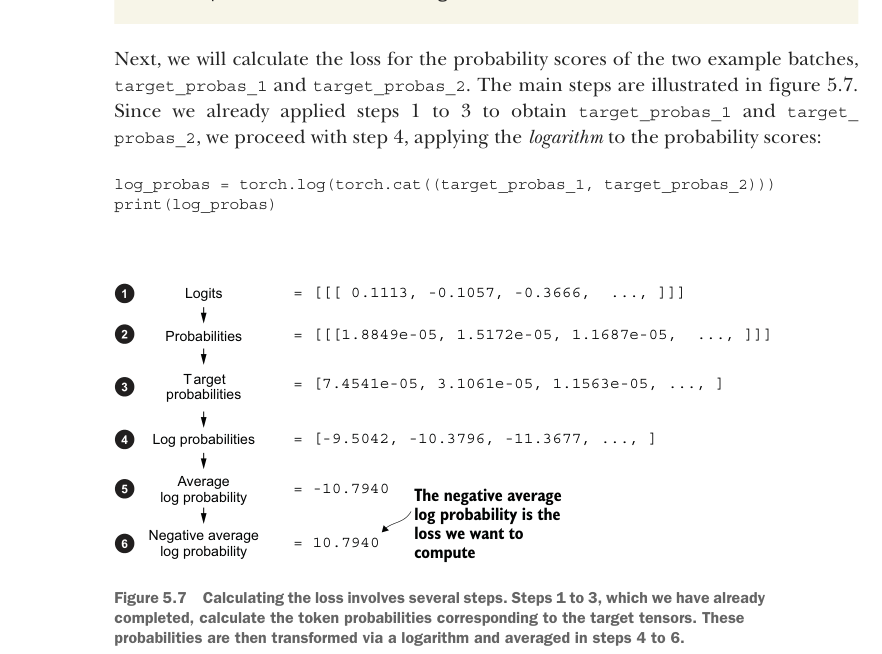
---


In [49]:
# ==============================================================
# Step-by-Step Manual Calculation of Cross-Entropy Loss
# ==============================================================

# Concatenate target probabilities across batches
combined_target_probas = torch.cat((target_probas_1, target_probas_2))

# Step 4: Apply logarithm
log_probas = torch.log(combined_target_probas)
print("Log probabilities:\n", log_probas)

# Step 5: Compute average log probability
avg_log_probas = torch.mean(log_probas)
print(f"Average log probability: {avg_log_probas.item():.4f}")

# Step 6: Negative average log probability (Cross-Entropy Loss)
neg_avg_log_probas = avg_log_probas * -1
print(f"Manual Cross-Entropy Loss: {neg_avg_log_probas.item():.4f}")


Log probabilities:
 tensor([-10.0457, -10.3132, -10.8261, -11.0039, -11.3664, -11.3357])
Average log probability: -10.8152
Manual Cross-Entropy Loss: 10.8152


In [50]:
# ==============================================================
# Computing Loss via PyTorch's Built-in cross_entropy Function
# ==============================================================

# Flatten logits from [batch, seq_len, vocab_size] to [batch * seq_len, vocab_size]
logits_flat = logits.flatten(0, 1)

# Flatten targets from [batch, seq_len] to [batch * seq_len]
targets_flat = targets.flatten()

print("Flattened logits shape: ", logits_flat.shape)   # [6, 50257]
print("Flattened targets shape:", targets_flat.shape)  # [6]

# Calculate cross entropy loss
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(f"PyTorch F.cross_entropy Loss: {loss.item():.4f}")

# Verify exact match
assert math.isclose(neg_avg_log_probas.item(), loss.item(), rel_tol=1e-5), "Loss mismatch!"
print("Verification successful: Manual calculation matches PyTorch cross_entropy exactly!")


Flattened logits shape:  torch.Size([6, 50257])
Flattened targets shape: torch.Size([6])
PyTorch F.cross_entropy Loss: 10.8152
Verification successful: Manual calculation matches PyTorch cross_entropy exactly!


### Q.6) What Is Perplexity in Language Modeling and What Does Its Numerical Value Represent?

**Answer:**

1. **Definition:**
   - Perplexity is defined mathematically as the exponential of the cross-entropy loss:
     $$\\text{Perplexity} = \\exp(\\text{Loss}) = e^{\\text{Cross-Entropy Loss}}$$
2. **Intuitive Interpretation ("Effective Vocabulary Size"):**
   - Perplexity measures the model's uncertainty when predicting the next token. A perplexity of $K$ means the model is as confused as if it were choosing uniformly at random among $K$ possible tokens.
3. **Untrained Baseline:**
   - For an untrained model with loss $\\approx 10.79$, $\\text{Perplexity} = e^{10.7940} \\approx 48,725$. This indicates the model is essentially uncertain across nearly all $50,257$ vocabulary entries.
   - As training progresses and loss decreases to $\\approx 0.39$, perplexity drops to $e^{0.39} \\approx 1.48$, meaning the model predicts subsequent words with high confidence.


In [51]:
# ==============================================================
# Calculating Perplexity
# ==============================================================

perplexity = torch.exp(loss)
print(f"Calculated Perplexity: {perplexity.item():.2f}")
print(f"Total Vocabulary Size: {GPT2_CONFIG['vocab_size']}")
print(f"Interpretation: The untrained model is uncertain among ~{int(perplexity.item())} tokens at each step.")


Calculated Perplexity: 49769.89
Total Vocabulary Size: 50257
Interpretation: The untrained model is uncertain among ~49769 tokens at each step.


# 5.1.3 Streaming Dataset and DataLoader Architecture (100M Tokens)

When working with large real-world corpora (such as a 12 GB raw text dataset on Kaggle), standard `file.read()` causes the **kernel to crash with Out Of Memory (OOM)**. 

To solve this, our dataset architecture:
1. **Streams in 10 MB Chunks:** Only small buffers are loaded into RAM.
2. **Delimits on `<|endoftext|>`:** Complete paragraphs/documents are preserved with internal formatting, newlines, and `<|endoftext|>` token IDs (`50256`).
3. **Stops Automatically at 100 Million Tokens:** As soon as 100M tokens are tokenized, reading terminates.
4. **Memory Footprint:** Uses a single `np.uint16` array consuming **only ~200 MB of RAM**!
5. **On-the-Fly Batch Slicing:** Avoids creating millions of redundant PyTorch tensor objects.

---
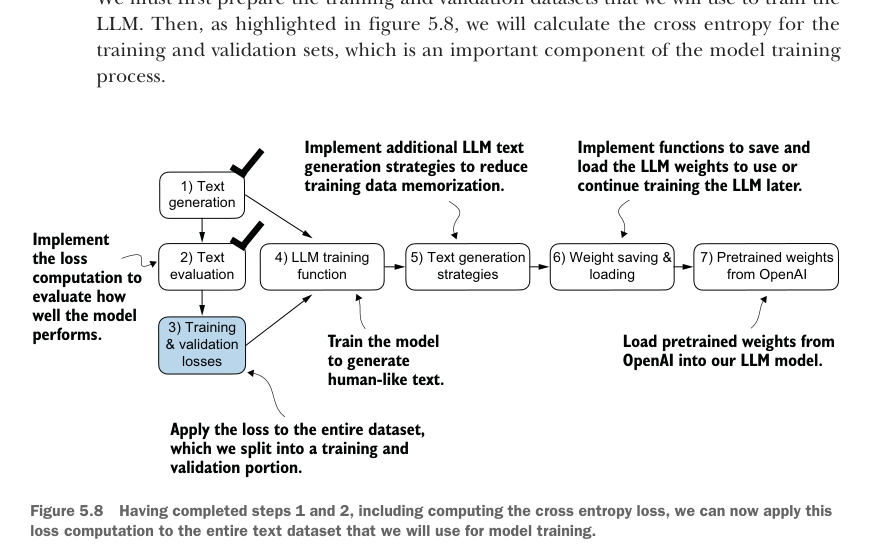
---


### Q.7) How Do We Chunk and Batch Continuous Unlabeled Text for LLM Pretraining?

**Answer:**

1. **Train/Validation Partitioning:**
   - We split the collected 100M tokens into $90\\%$ for training (90M tokens) and $10\\%$ for validation (10M tokens).
2. **Sliding Window Chunking:**
   - Continuous token streams are divided into input sequences of fixed length (`context_length = 256`).
   - Using `stride = 256` ensures non-overlapping sequences during pretraining so that the model observes all tokens efficiently.
3. **Batch Shuffling and Dropping:**
   - Training batches are randomly shuffled (`shuffle = True`) to prevent cyclic gradient patterns.
   - `drop_last = True` drops the final incomplete batch to avoid erratic loss spikes from mismatched batch sizes.

---
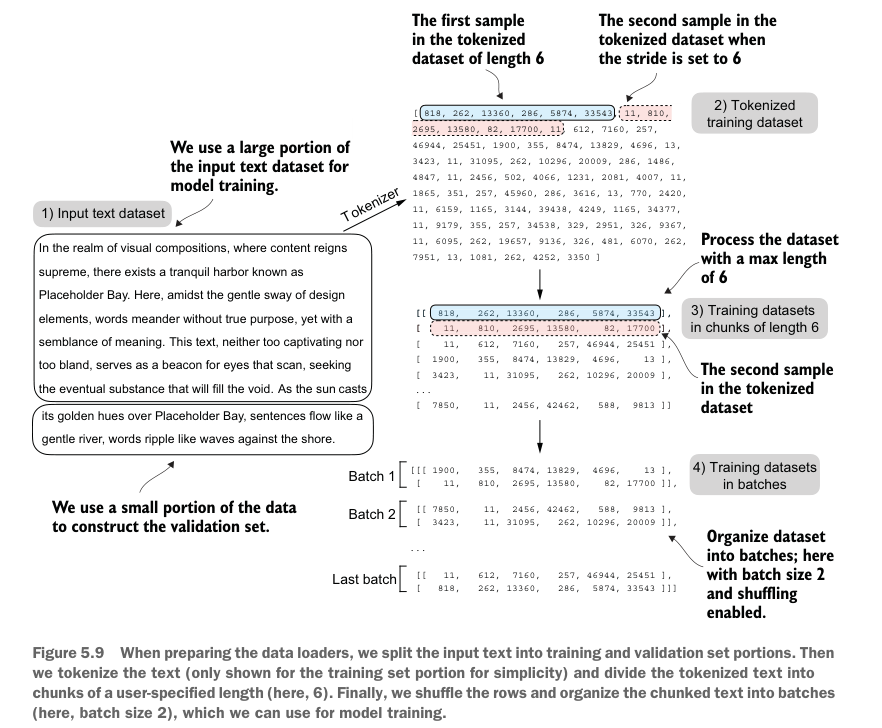
---


In [52]:
# ==============================================================
# High-Speed Multi-Threaded Streaming Dataset Class
# ==============================================================
import itertools

class GPTPretrainingDataset(Dataset):
    def __init__(self, file_path, context_length=256, stride=256, max_tokens=100_000_000):
        self.context_length = context_length
        self.stride = stride
        self.tokenizer = tiktoken.get_encoding("gpt2")
        
        # Pre-allocate exactly max_tokens in uint16 (Only ~1.4 GB RAM for 700M tokens!)
        self.tokens = np.empty(max_tokens, dtype=np.uint16)
        tokens_collected = 0
        
        delimiter = "<|endoftext|>"
        remainder = ""
        chunk_size = 64 * 1024 * 1024  # High-speed 64 MB I/O read buffer
        
        print(f"Streaming and tokenizing from '{file_path}' up to {max_tokens:,} tokens (64 MB buffers, multi-threaded)...")
        pbar = tqdm(total=max_tokens, unit="tokens")
        
        with open(file_path, "r", encoding="utf-8", errors="ignore") as file:
            while tokens_collected < max_tokens:
                chunk = file.read(chunk_size)
                if not chunk:
                    # End of file reached
                    if remainder:
                        new_tokens = self.tokenizer.encode(remainder, allowed_special={delimiter})
                        needed = min(len(new_tokens), max_tokens - tokens_collected)
                        self.tokens[tokens_collected:tokens_collected + needed] = new_tokens[:needed]
                        tokens_collected += needed
                        pbar.update(needed)
                    break
                
                text = remainder + chunk
                last_delim_idx = text.rfind(delimiter)
                
                if last_delim_idx != -1:
                    # Slice text strictly up to the last <|endoftext|> delimiter
                    process_text = text[:last_delim_idx + len(delimiter)]
                    remainder = text[last_delim_idx + len(delimiter):]
                else:
                    # No delimiter found in this 64MB chunk; accumulate into remainder
                    remainder = text
                    continue
                
                # Split chunk into individual documents preserving delimiter
                parts = process_text.split(delimiter)
                docs = [p + delimiter for p in parts[:-1]]
                
                # Fast multi-threaded batch tokenization across CPU cores (releases Python GIL)
                batch_tokens = self.tokenizer.encode_batch(docs, num_threads=4, allowed_special={delimiter})
                new_tokens = list(itertools.chain.from_iterable(batch_tokens))
                num_new = len(new_tokens)
                
                if tokens_collected + num_new >= max_tokens:
                    needed = max_tokens - tokens_collected
                    self.tokens[tokens_collected:max_tokens] = new_tokens[:needed]
                    tokens_collected = max_tokens
                    pbar.update(needed)
                    break
                else:
                    self.tokens[tokens_collected:tokens_collected + num_new] = new_tokens
                    tokens_collected += num_new
                    pbar.update(num_new)
                    
        pbar.close()
        
        # If the file ended before reaching max_tokens, resize array to actual size
        if tokens_collected < max_tokens:
            self.tokens = self.tokens[:tokens_collected]
            
        self.total_tokens = tokens_collected
        print(f"[✓] Successfully tokenized {self.total_tokens:,} tokens (~{self.tokens.nbytes / (1024**2):.1f} MB RAM).")

    def __len__(self):
        return (self.total_tokens - self.context_length) // self.stride

    def __getitem__(self, idx):
        start_idx = idx * self.stride
        x = self.tokens[start_idx : start_idx + self.context_length]
        y = self.tokens[start_idx + 1 : start_idx + 1 + self.context_length]
        return torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)


class TokenSubDataset(Dataset):
    """Zero-copy slice view for training and validation splits."""
    def __init__(self, token_array, context_length, stride):
        self.tokens = token_array
        self.context_length = context_length
        self.stride = stride
        self.total_tokens = len(token_array)

    def __len__(self):
        return (self.total_tokens - self.context_length) // self.stride

    def __getitem__(self, idx):
        start_idx = idx * self.stride
        x = self.tokens[start_idx : start_idx + self.context_length]
        y = self.tokens[start_idx + 1 : start_idx + 1 + self.context_length]
        return torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)


In [53]:
# ==============================================================
# Configuring Dataset File Path and Target Token Count
# ==============================================================

# Kaggle raw text dataset path
KAGGLE_PATH = "/kaggle/input/datasets/singhtech10/gpt2-1b-token-pretraining-dataset/gpt2_1B_token_pretraining_dataset.txt"
# LOCAL_PATH = "the-verdict.txt"

# Set target tokens: 700M for pretraining!
TARGET_TOKENS = 700_000_000

# Automatically detect Kaggle environment or fallback to local
if os.path.exists(KAGGLE_PATH):
    dataset_file = KAGGLE_PATH
    print(f"Running on Kaggle: Detected raw text dataset at {dataset_file}")
# elif os.path.exists(LOCAL_PATH):
#     dataset_file = LOCAL_PATH
#     print(f"Running locally: Detected dataset at {dataset_file}")
# else:
#     print(f"Downloading sample dataset {LOCAL_PATH}...")
#     url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"
#     urllib.request.urlretrieve(url, LOCAL_PATH)
#     dataset_file = LOCAL_PATH

# Initialize streaming dataset
full_dataset = GPTPretrainingDataset(
    file_path=dataset_file,
    context_length=GPT2_CONFIG["context_length"],
    stride=GPT2_CONFIG["context_length"],
    max_tokens=TARGET_TOKENS
)


Running on Kaggle: Detected raw text dataset at /kaggle/input/datasets/singhtech10/gpt2-1b-token-pretraining-dataset/gpt2_1B_token_pretraining_dataset.txt
Streaming and tokenizing from '/kaggle/input/datasets/singhtech10/gpt2-1b-token-pretraining-dataset/gpt2_1B_token_pretraining_dataset.txt' up to 700,000,000 tokens (64 MB buffers, multi-threaded)...


  0%|          | 0/700000000 [00:00<?, ?tokens/s]

wandb: WARNING Fatal error while uploading data. Some run data will not be synced, but it will still be written to disk. Use `wandb sync` at the end of the run to try uploading.


KeyboardInterrupt: 

In [ ]:
# ==============================================================
# Preparing Train and Validation Datasets
# ==============================================================

# Split 90% Training, 10% Validation
train_ratio = 0.90
split_idx = int(train_ratio * full_dataset.total_tokens)

train_tokens = full_dataset.tokens[:split_idx]
val_tokens = full_dataset.tokens[split_idx:]

train_dataset = TokenSubDataset(
    train_tokens,
    context_length=GPT2_CONFIG["context_length"],
    stride=GPT2_CONFIG["context_length"]
)
val_dataset = TokenSubDataset(
    val_tokens,
    context_length=GPT2_CONFIG["context_length"],
    stride=GPT2_CONFIG["context_length"]
)

print(f"Total training tokens:   {len(train_tokens):,}")
print(f"Total validation tokens: {len(val_tokens):,}")


In [ ]:
# ==============================================================
# Batch and DataLoader Loss Utility Functions
# ==============================================================

def calc_loss_batch(input_batch, target_batch, model, device):
    """
    Computes cross-entropy loss for a single input-target batch on target device.
    """
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    """
    Computes average loss across all batches in a DataLoader.
    """
    total_loss = 0.0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches


In [ ]:
print_model_parameters(model)

In [ ]:
# # ==============================================================
# # Baseline Loss Evaluation of Untrained Model
# # ==============================================================

# model.to(device)

# # Build a temporary test loader to evaluate baseline loss
# temp_loader = DataLoader(train_dataset, batch_size=16, shuffle=False)

# with torch.no_grad():
#     train_loss = calc_loss_loader(temp_loader, model, device, num_batches=10)

# print(f"Untrained Initial Training Loss:   {train_loss:.4f}")
# print(f"Untrained Initial Perplexity:      {math.exp(train_loss):.2f}")


# 5.2 Pretraining the LLM from Scratch with HF Auto-Batch Scaling & W&B

With evaluation metrics in place, we now implement the training loop to optimize our model parameters.

---
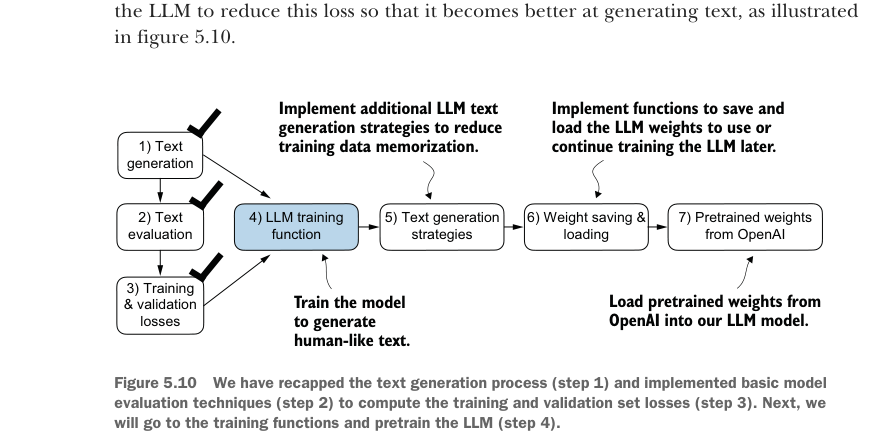
---


### Q.8) What Are the Essential Steps in a PyTorch LLM Training Loop?

**Answer:**

A standard deep neural network training loop in PyTorch consists of 8 sequential steps per epoch:
1. **Epoch Iteration:** Loop over a predefined number of complete passes over the training set (`num_epochs`).
2. **Batch Iteration:** Sample mini-batches of inputs and shifted targets from the `DataLoader`.
3. **Gradient Reset (`optimizer.zero_grad()`):** Clear accumulated gradients from previous batch iterations.
4. **Forward Pass & Loss Calculation (`calc_loss_batch`):** Pass inputs through the model and compute Cross-Entropy Loss against targets.
5. **Backward Pass (`loss.backward()`):** Compute loss gradients with respect to all trainable parameters via backpropagation.
6. **Weight Update (`optimizer.step()`):** Update parameters in the opposite direction of the gradient.
7. **Loss Evaluation (`evaluate_model`):** Periodically evaluate training and validation losses in `eval()` mode with gradient tracking disabled (`torch.no_grad()`).
8. **Sample Text Generation (`generate_and_print_sample`):** Visually monitor linguistic quality by prompting the model to generate text after each epoch.

---
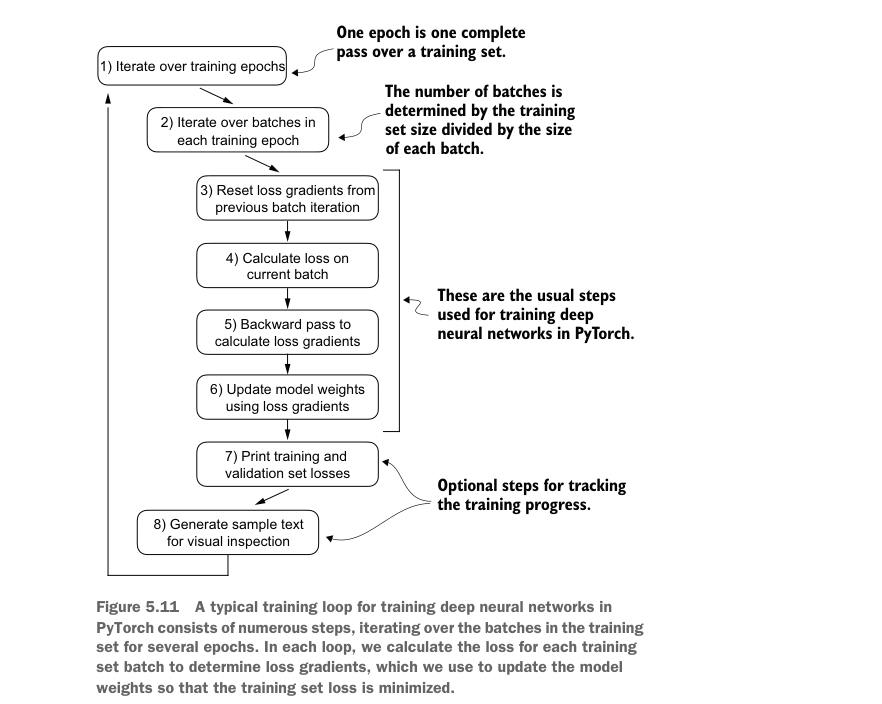
---


### Q.9) Why Is AdamW Preferred Over Standard Adam or SGD for Training LLMs?

**Answer:**

1. **Decoupled Weight Decay:**
   - In standard Adam, L2 weight regularization is added directly to the loss gradients, which gets scaled down by Adam's adaptive second moment running average ($v_t$). This weakens regularization for parameters with large gradient history.
   - **AdamW (Adam with Weight Decay)** directly subtracts a fraction of the current weight ($\theta_t \leftarrow \theta_t - \gamma \lambda \theta_t$) independently of gradient updates, restoring true L2 weight decay regularization.
2. **Effective Generalization:**
   - Decoupled weight decay prevents weights from growing excessively large, suppressing overfitting and stabilizing multi-layer Transformer training.
3. **Adaptive Learning Rates:**
   - Like Adam, AdamW maintains moving averages of both past gradients (momentum) and squared gradients (variance), enabling robust per-parameter adaptive learning rates.


In [ ]:
# ==============================================================
# Weights & Biases (W&B) Setup & Kaggle Secrets Authentication
# ==============================================================

# W&B Configuration
WANDB_PROJECT = "gpt2-pretraining-from-scratch"
WANDB_RUN_NAME = "gpt2-70m-700m-tokens"

# Set to an existing W&B run ID (e.g. "a1b2c3d4") to resume; leave None for a fresh run
RESUME_RUN_ID = None

# Authenticate securely using Kaggle Secrets (Add-ons -> Secrets -> WANDB_API_KEY)
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    wandb_key = user_secrets.get_secret("WANDB_API_KEY")
    wandb.login(key=wandb_key)
    print("[✓] Logged in to Weights & Biases via Kaggle Secrets.")
except Exception as e:
    print("Kaggle Secret 'WANDB_API_KEY' not found; falling back to interactive login...")
    wandb.login()

# Initialize or Resume W&B Run
if RESUME_RUN_ID:
    run = wandb.init(
        project=WANDB_PROJECT,
        id=RESUME_RUN_ID,
        resume="must"
    )
    print(f"[✓] Resumed existing W&B run: {run.name} (ID: {run.id})")
else:
    run = wandb.init(
        project=WANDB_PROJECT,
        name=WANDB_RUN_NAME,
        config={
            **GPT2_CONFIG,
            "target_tokens": TARGET_TOKENS,
            "optimizer": "AdamW",
            "learning_rate": 0.0004,
            "weight_decay": 0.1,
            "num_gpus": num_gpus
        }
    )
    print(f"[✓] Started fresh W&B run: {run.name} (ID: {run.id})")


In [ ]:
# ==============================================================
# Evaluation and Sample Generation Monitoring Utilities
# ==============================================================

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """
    Evaluates training and validation loss with dropout disabled.
    """
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context, max_new_tokens=50):
    """
    Generates a sample text continuation to qualitatively monitor training progress.
    Clearly separates the input prompt from the model-generated output continuation.
    Supports both single-GPU and DataParallel models.
    """
    model.eval()
    raw_model = model.module if hasattr(model, "module") else model
    context_size = raw_model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=raw_model,
            idx=encoded,
            max_new_tokens=max_new_tokens,
            context_size=context_size
        )
    
    # Isolate only newly generated continuation tokens
    new_token_ids = token_ids[:, encoded.shape[1]:]
    generated_output = token_ids_to_text(new_token_ids, tokenizer).replace("\n", " ").strip()
    clean_prompt = start_context.replace("\n", " ").strip()
    
    print(f'  ├── [Input] : "{clean_prompt}"')
    print(f'  └── [Output]: "{generated_output}"')
    model.train()
    return generated_output


In [ ]:
# ==============================================================
# Pretraining Loop with W&B Logging, Artifacts & Best Model Tracking
# ==============================================================

def train_model_wandb(model, train_loader, val_loader,
                      optimizer, device, num_epochs,
                      eval_freq, eval_iter, start_context, tokenizer,
                      sample_max_new_tokens=50,
                      save_freq=500,
                      start_epoch=0, start_step=0, start_tokens_seen=0,
                      best_val_loss=float("inf"), run=None):
    """
    Pretraining loop tracking loss, perplexity, periodic checkpointing every
    save_freq steps, uploading checkpoints to W&B Artifacts, and tagging the best frozen model.
    """
    import time
    
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen = start_tokens_seen
    global_step = start_step - 1

    # Total training steps and timer for speed/ETA calculation
    total_steps = len(train_loader) * num_epochs
    start_time = time.time()

    # W&B sample generation history list
    sample_history = []

    def format_tokens(n):
        if n >= 1_000_000:
            return f"{n / 1_000_000:.2f}M"
        elif n >= 1_000:
            return f"{n / 1_000:.1f}K"
        return str(n)

    def format_speed(tok_per_sec):
        if tok_per_sec >= 1_000:
            return f"{tok_per_sec / 1_000:4.1f}k tok/s"
        return f"{tok_per_sec:4.0f} tok/s"

    def save_and_upload_checkpoint(ckpt_name, description, aliases=None, is_best=False, epoch_checkpoint=None):
        """Helper to save and upload model state dict to W&B."""
        raw_model = model.module if hasattr(model, "module") else model
        save_epoch = epoch if epoch_checkpoint is None else epoch_checkpoint
        checkpoint_data = {
            "epoch": save_epoch,
            "global_step": global_step,
            "tokens_seen": tokens_seen,
            "model_state_dict": raw_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "config": GPT2_CONFIG
        }
        os.makedirs("checkpoints", exist_ok=True)
        file_path = f"checkpoints/{ckpt_name}"
        torch.save(checkpoint_data, file_path)

        if run is not None:
            artifact_name = f"{run.id}-best-model" if is_best else f"{run.id}-checkpoint"
            artifact = wandb.Artifact(
                name=artifact_name,
                type="model",
                description=description
            )
            artifact.add_file(file_path)
            run.log_artifact(artifact, aliases=aliases or [])

    for epoch in range(start_epoch, num_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()
            optimizer.step()

            tokens_seen += input_batch.numel()
            global_step += 1

            # Periodic evaluation every eval_freq steps
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                train_ppl = math.exp(min(train_loss, 20))
                val_ppl = math.exp(min(val_loss, 20))

                # Calculate throughput speed & ETA
                elapsed = time.time() - start_time
                tokens_since_start = tokens_seen - start_tokens_seen
                steps_done = max(1, (global_step + 1) - start_step)
                steps_remaining = max(0, total_steps - (global_step + 1))

                if elapsed > 1.0 and tokens_since_start > 0:
                    tok_per_sec = tokens_since_start / elapsed
                    time_per_step = elapsed / steps_done
                    eta_seconds = int(steps_remaining * time_per_step)
                    eta_str = time.strftime("%H:%M:%S", time.gmtime(eta_seconds))
                else:
                    tok_per_sec = 0
                    eta_str = "--:--:--"

                pct = ((global_step + 1) / total_steps) * 100.0 if total_steps > 0 else 0.0

                # Status badge determination
                is_saved_ckpt = (global_step > 0 and global_step % save_freq == 0)
                is_new_best = False

                # Check for new best validation loss
                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    is_new_best = True
                    save_and_upload_checkpoint(
                        ckpt_name="best_model.pth",
                        description=f"Best frozen model with val_loss={best_val_loss:.4f} at step {global_step}",
                        aliases=["best", "frozen"],
                        is_best=True
                    )

                # Periodic Checkpoint Save & W&B Upload
                if is_saved_ckpt:
                    save_and_upload_checkpoint(
                        ckpt_name="checkpoint-latest.pth",
                        description=f"Pretraining checkpoint at step {global_step}",
                        aliases=["latest"],
                        is_best=False
                    )

                if global_step == start_step:
                    status = "Baseline"
                elif is_new_best and is_saved_ckpt:
                    status = "★ Best Val! (💾 CKPT Saved)"
                elif is_new_best:
                    status = "★ Best Val!"
                elif is_saved_ckpt:
                    status = "💾 CKPT Saved"
                else:
                    status = ""

                # Print formatted single-line log
                print(f"[Ep {epoch+1}/{num_epochs} | Step {global_step:06d}/{total_steps} | {pct:5.1f}%] | "
                      f"Train: {train_loss:.3f} (PPL: {train_ppl:7.1f}) | "
                      f"Val: {val_loss:.3f} (PPL: {val_ppl:7.1f}) | "
                      f"Tokens: {format_tokens(tokens_seen):>6} ({format_speed(tok_per_sec):>11}) | "
                      f"ETA: {eta_str} | {status}")

                # Prepare W&B log payload
                log_data = {
                    "epoch": epoch + 1,
                    "global_step": global_step,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "train_ppl": train_ppl,
                    "val_ppl": val_ppl,
                    "tokens_seen": tokens_seen,
                    "tokens_per_sec": tok_per_sec,
                    "learning_rate": optimizer.param_groups[0]["lr"]
                }

                # Sample generation: only at baseline (step 0) and every save_freq (500) steps
                if global_step == start_step or is_saved_ckpt:
                    sample_text = generate_and_print_sample(
                        model, tokenizer, device, start_context, max_new_tokens=sample_max_new_tokens
                    )
                    if run is not None:
                        sample_history.append([epoch + 1, global_step, start_context, sample_text])
                        log_data["generation_samples"] = wandb.Table(
                            columns=["epoch", "global_step", "prompt", "generated_text"],
                            data=[list(r) for r in sample_history]
                        )

                if run is not None:
                    wandb.log(log_data, step=global_step)

            # Periodic Checkpoint Save if save_freq falls on non-eval step
            elif global_step > 0 and global_step % save_freq == 0:
                save_and_upload_checkpoint(
                    ckpt_name="checkpoint-latest.pth",
                    description=f"Pretraining checkpoint at step {global_step}",
                    aliases=["latest"],
                    is_best=False
                )
                print(f"[✓] Periodic checkpoint uploaded to W&B Artifacts (Step {global_step:06d})")

        # Generate sample text after epoch
        sample_text = generate_and_print_sample(
            model, tokenizer, device, start_context, max_new_tokens=sample_max_new_tokens
        )
        if run is not None:
            sample_history.append([epoch + 1, global_step, start_context, sample_text])
            wandb.log({
                "generation_samples": wandb.Table(
                    columns=["epoch", "global_step", "prompt", "generated_text"],
                    data=[list(r) for r in sample_history]
                )
            }, step=global_step)

        # Checkpoint at end of epoch (record next epoch for resume)
        save_and_upload_checkpoint(
            ckpt_name="checkpoint-latest.pth",
            description=f"Pretraining checkpoint at end of epoch {epoch+1}",
            aliases=["latest"],
            is_best=False,
            epoch_checkpoint=epoch + 1
        )
        print(f"[✓] Checkpoint uploaded to W&B Artifacts (End of Epoch {epoch+1})")

    return train_losses, val_losses, track_tokens_seen, best_val_loss


### Q.10) How Do We Automatically Find the Optimal Batch Size on GPU Without Out-of-Memory (OOM) Errors?

**Answer:**

1. **The Batch Size Dilemma:**
   - **Too Large:** Exceeds GPU Video RAM (VRAM), raising `torch.cuda.OutOfMemoryError` and abruptly killing the training kernel.
   - **Too Small:** Underutilizes GPU Tensor Cores, increases gradient variance, and severely extends overall wall-clock training time.
   - **Target:** On Kaggle's dual NVIDIA T4 GPUs (~30 GB total VRAM across 2 devices), we want the largest possible batch size that safely fits into memory while maximizing training throughput.

2. **Does PyTorch Have a Built-In Method?**
   - **Vanilla PyTorch (`torch`):** PyTorch core does **not** provide a built-in automated batch size finder. Developers traditionally resort to manual trial-and-error.
   - **PyTorch Lightning (`Tuner.scale_batch_size`):** While Lightning offers a `Tuner`, it strictly mandates refactoring the model into a `LightningModule` and handing full control to `pl.Trainer`. This destroys educational, from-scratch PyTorch training loops and introduces heavy framework overhead.

3. **The Hugging Face Accelerate Solution (`find_executable_batch_size`):**
   - Hugging Face provides `@find_executable_batch_size(starting_batch_size=256)`, an elegant, framework-agnostic decorator for vanilla PyTorch training functions.
   - **How It Works:**
     1. It begins execution with the requested maximum starting batch size ($256$).
     2. If a CUDA Out-of-Memory error occurs during execution, it catches the exception.
     3. It flushes GPU memory allocations via `gc.collect()` and `torch.cuda.empty_cache()`.
     4. It automatically cuts the batch size in half ($256 \to 128 \to 64 \to 32 \dots$) and re-runs the function.
     5. If memory allows, execution completes seamlessly at the highest viable batch size without manual intervention.

4. **Multi-GPU Parallelism (`torch.nn.DataParallel`):**
   - When multiple GPUs are detected (`torch.cuda.device_count() > 1`), the batch size is divided across the GPUs ($128$ tokens per batch per T4 GPU for a global batch size of $256$).
   - The effective batch size is logged to Weights & Biases (`run.config.update`) so you always have full visibility into your actual training configuration.


In [ ]:
# ==============================================================
# Hugging Face find_executable_batch_size: Automated Batch Scaling
# ==============================================================

# Global training tracking results
training_results = {}

# Use Hugging Face Accelerate's find_executable_batch_size
# Starting from 256. If CUDA OOM occurs, it halves it (256 -> 128 -> 64 -> 32) automatically!
@find_executable_batch_size(starting_batch_size=256)
def run_pretraining(batch_size):
    global training_results
    print(f"\n========================================================")
    print(f"Testing / Executing Training with Batch Size: {batch_size}")
    if num_gpus > 1:
        print(f"  -> Effective per-GPU Batch Size: {batch_size // num_gpus}")
    print(f"========================================================")
    
    # 1. Clear GPU cache
    gc.collect()
    torch.cuda.empty_cache()
    
    # 2. Build DataLoaders with the auto-selected batch size
    effective_batch_size = min(batch_size, max(1, len(train_dataset)))
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=effective_batch_size,
        shuffle=True,
        drop_last=(len(train_dataset) > effective_batch_size),
        num_workers=2 if torch.cuda.is_available() else 0
    )
    val_loader = DataLoader(
        dataset=val_dataset,
        batch_size=effective_batch_size,
        shuffle=False,
        drop_last=False,
        num_workers=2 if torch.cuda.is_available() else 0
    )
    
    # 3. Initialize Model and Multi-GPU Support
    torch.manual_seed(123)
    base_model = GPTModel(GPT2_CONFIG)
    
    if num_gpus > 1:
        print(f"[✓] Multi-GPU Active: Wrapping model in DataParallel across {num_gpus} GPUs.")
        train_model = nn.DataParallel(base_model)
    else:
        train_model = base_model
        
    train_model.to(device)
    
    # 4. Initialize Optimizer
    optimizer = torch.optim.AdamW(
        train_model.parameters(),
        lr=0.0004,
        weight_decay=0.1
    )
    
    start_epoch = 0
    start_step = 0
    start_tokens_seen = 0
    best_val_loss = float("inf")
    
    # Resume from W&B Checkpoint if RESUME_RUN_ID is set
    if RESUME_RUN_ID and run is not None:
        try:
            artifact = run.use_artifact(f"{WANDB_PROJECT}/{RESUME_RUN_ID}-checkpoint:latest")
            artifact_dir = artifact.download(root="checkpoints_downloaded")
            ckpt_file = os.path.join(artifact_dir, "checkpoint-latest.pth")
            
            checkpoint = torch.load(ckpt_file, map_location=device)
            raw_target = train_model.module if hasattr(train_model, "module") else train_model
            raw_target.load_state_dict(checkpoint["model_state_dict"])
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
            start_epoch = checkpoint.get("epoch", 0)
            start_step = checkpoint.get("global_step", -1) + 1
            start_tokens_seen = checkpoint.get("tokens_seen", 0)
            best_val_loss = checkpoint.get("best_val_loss", float("inf"))
            print(f"[✓] Resumed from W&B run {RESUME_RUN_ID} (Epoch {start_epoch+1}, Step {start_step})")
        except Exception as e:
            print(f"Failed to resume artifact: {e}; starting fresh training.")
            
    # Update W&B config with final active batch size
    if run is not None:
        run.config.update({"batch_size": batch_size, "per_gpu_batch_size": batch_size // max(1, num_gpus)}, allow_val_change=True)

    # 5. Execute Training Loop
    num_epochs = 2
    train_losses, val_losses, tokens_seen, best_val_loss = train_model_wandb(
        model=train_model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        device=device,
        num_epochs=num_epochs,
        eval_freq=500,
        eval_iter=10,
        start_context=user_prompt,
        tokenizer=tokenizer,
        sample_max_new_tokens=20,
        save_freq=500,
        start_epoch=start_epoch,
        start_step=start_step,
        start_tokens_seen=start_tokens_seen,
        best_val_loss=best_val_loss,
        run=run
    )
    
    # Store output results
    training_results["model"] = train_model
    training_results["train_losses"] = train_losses
    training_results["val_losses"] = val_losses
    training_results["tokens_seen"] = tokens_seen
    training_results["best_val_loss"] = best_val_loss
    training_results["batch_size"] = batch_size
    training_results["num_epochs"] = num_epochs
    print(f"\n[✓] Pretraining completed successfully with batch_size={batch_size}!")

# Execute Auto-Scaling Training
run_pretraining()


In [ ]:
# ==============================================================
# Visualizing Training vs Validation Loss Curves
# ==============================================================

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(6, 4))
    ax1.plot(epochs_seen, train_losses, label="Training loss", color="tab:blue")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss", color="tab:orange")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Cross-Entropy Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    # Dual x-axis for total tokens seen
    ax2 = ax1.twiny()
    ax2.plot(tokens_seen, train_losses, alpha=0)
    ax2.set_xlabel("Tokens Seen")

    plt.title(f"Pretraining Loss Convergence (Batch Size: {training_results.get('batch_size', 'auto')})")
    fig.tight_layout()
    plt.show()

epochs_tensor = torch.linspace(0, training_results.get("num_epochs", 1), len(training_results.get("train_losses", [])))
plot_losses(epochs_tensor, training_results.get("tokens_seen", []), training_results.get("train_losses", []), training_results.get("val_losses", []))


### Q.11) Why Do Training and Validation Losses Diverge, and How Do We Recognize Overfitting?

**Answer:**

1. **Loss Divergence:**
   - In early epochs, both training loss and validation loss drop rapidly.
   - When training on small corpora, the training loss steadily converges towards $0.39$, while validation loss stalls and begins to rise ($6.45$).
2. **Diagnosis (Verbatim Memorization):**
   - If parameter capacity vastly exceeds dataset size, the network memorizes the text verbatim rather than discovering general syntactic rules.
   - Searching generated snippets confirms they match the source text word-for-word.
3. **Real-World Contrast (100M+ Tokens):**
   - Training on a large 100M-token corpus provides high vocabulary diversity, allowing the model to learn robust generalization instead of rote memorization.

---
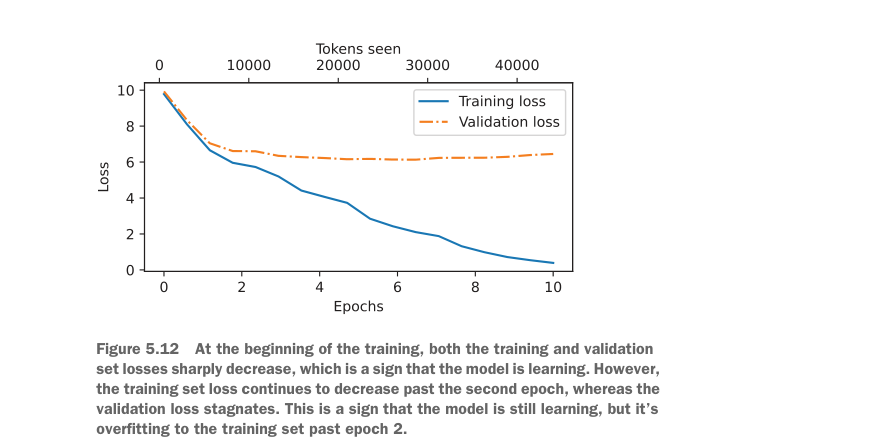
---
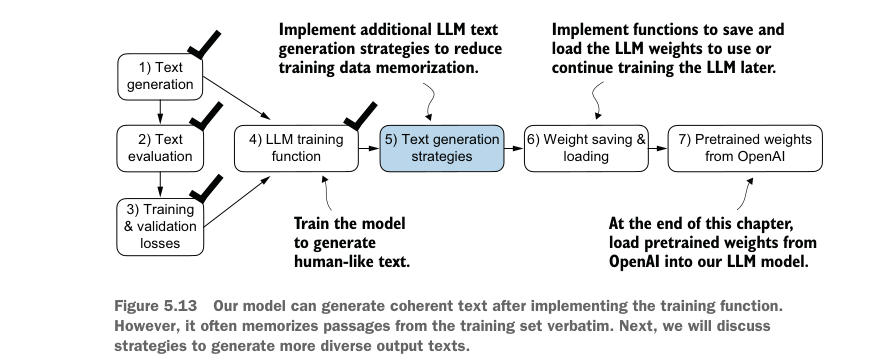
---


# 5.3 Decoding Strategies to Control Randomness

### Q.12) What Is Greedy Decoding, What Are Its Limitations, and How Does Probabilistic Sampling Help?

**Answer:**

1. **Greedy Decoding:**
   - Always selects the single token with the highest predicted probability: $\\text{next\\_token} = \\text{argmax}(P)$.
   - **Limitation:** It is strictly deterministic. Prompting the model with the same input always yields the exact same output, often falling into repetitive word loops or regurgitating memorized training sequences verbatim.
2. **Probabilistic Sampling:**
   - Instead of picking the maximum index, we treat the Softmax output as a categorical probability distribution and sample from it using `torch.multinomial`.
   - Highly probable tokens are chosen most often, but lower-probability tokens can still occasionally be selected, generating diverse, creative continuations.


In [ ]:
# ==============================================================
# Demonstrating Probabilistic Sampling with torch.multinomial
# ==============================================================

# Toy vocabulary
vocab = {
    "closer": 0, "every": 1, "effort": 2, "forward": 3,
    "inches": 4, "moves": 5, "pizza": 6, "toward": 7, "you": 8
}
inverse_vocab = {v: k for k, v in vocab.items()}

# Sample next-token logits
next_token_logits = torch.tensor([4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79])
probas = torch.softmax(next_token_logits, dim=0)

# Simulate 1,000 sampling iterations
def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item() for _ in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample), minlength=len(vocab))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq:3d} x {inverse_vocab[i]}")

print("Sampling frequencies over 1,000 runs:")
print_sampled_tokens(probas)


### Q.13) What Is Temperature Scaling and How Does It Reshape Probability Distributions?

**Answer:**

1. **Mathematical Formulation:**
   - Temperature scaling divides raw logits $z_i$ by a positive scalar $T > 0$ before applying the Softmax function:
     $$P(w_i) = \\frac{\\exp(z_i / T)}{\\sum_j \\exp(z_j / T)}$$
2. **Impact of Temperature Values:**
   - **$T = 1.0$ (Default):** Preserves original model logits; probabilities equal standard Softmax.
   - **$T < 1.0$ (Low Temperature):** Magnifies differences between logits, making the distribution sharper and peakier. As $T \\to 0$, it converges to greedy `argmax` decoding.
   - **$T > 1.0$ (High Temperature):** Compresses differences between logits, flattening probabilities towards a uniform distribution and encouraging creative, unpredictable word choices.

---
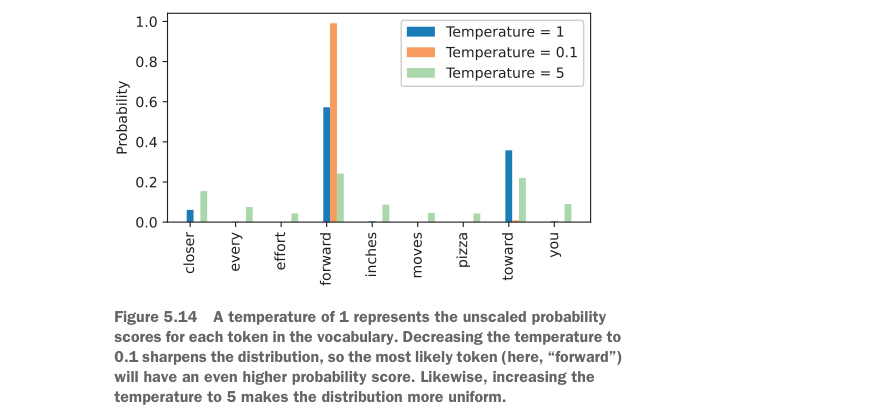
---


In [ ]:
# ==============================================================
# Temperature Scaling Implementation and Visualization
# ==============================================================

def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

temperatures = [1.0, 0.1, 5.0]
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

x = torch.arange(len(vocab))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, T in enumerate(temperatures):
    ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f"T = {T}")

ax.set_ylabel("Probability")
ax.set_title("Effect of Temperature Scaling on Softmax Distribution")
ax.set_xticks(x + bar_width)
ax.set_xticklabels(vocab.keys(), rotation=45)
ax.legend()
fig.tight_layout()
plt.show()


### Q.14) What Is Top-k Sampling and Why Is It Combined with Temperature Scaling?

**Answer:**

1. **Downside of Temperature Alone:**
   - When raising temperature to encourage creativity ($T > 1.0$), low-probability nonsense tokens (like *"pizza"* in the middle of a serious literary sentence) receive elevated odds and may be sampled.
2. **The Top-$k$ Mechanism:**
   - Top-$k$ sampling restricts the sampling candidate pool strictly to the $k$ tokens with the highest logits.
   - All tokens outside the top-$k$ set have their logits replaced with negative infinity ($-\\infty$).
   - When Softmax is computed, $e^{-\\infty} = 0$, guaranteeing zero probability for all non-top-$k$ tokens while the remaining top-$k$ probabilities re-normalize to sum to $1.0$.

---
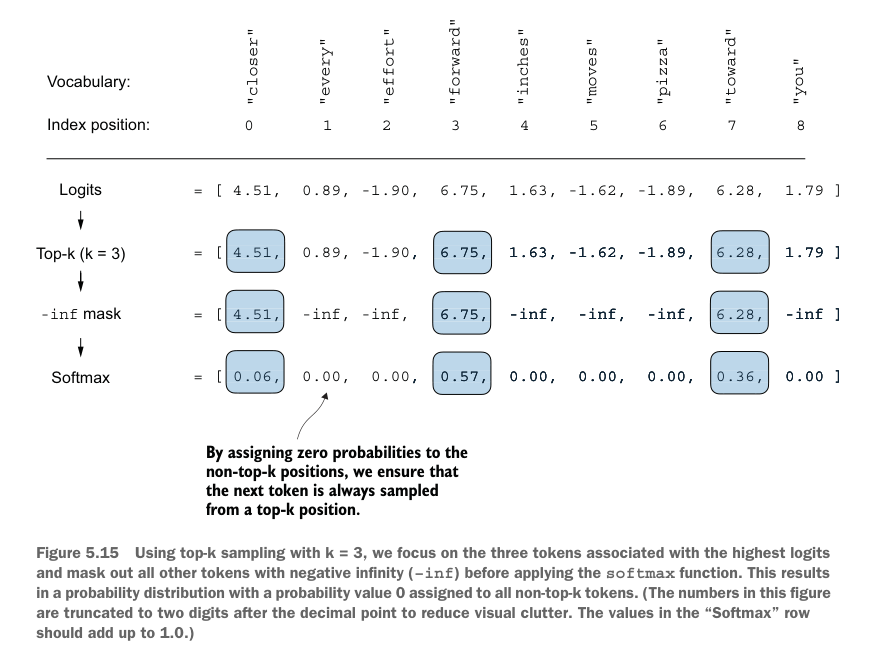
---


In [ ]:
# ==============================================================
# Implementing Top-k Filtering with torch.topk and torch.where
# ==============================================================

top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)

print("Top 3 logits:    ", top_logits)
print("Top 3 positions: ", top_pos)

# Set non-top-k logits to -infinity
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float('-inf')),
    other=next_token_logits
)
print("\nLogits after -inf masking:\n", new_logits)

topk_probas = torch.softmax(new_logits, dim=0)
print("\nProbabilities after top-k softmax:\n", topk_probas)


In [ ]:
# ==============================================================
# Versatile Generation Function with Temperature, Top-k, and EOS
# ==============================================================

def generate(model, idx, max_new_tokens, context_size,
             temperature=0.0, top_k=None, eos_id=None):
    """
    Advanced autoregressive generator supporting greedy decoding,
    temperature scaling, top-k filtering, and early EOS termination.
    """
    raw_model = model.module if hasattr(model, "module") else model
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = raw_model(idx_cond)
        logits = logits[:, -1, :]  # Last token logits

        # 1. Apply Top-k filtering
        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float('-inf')).to(logits.device),
                logits
            )

        # 2. Apply Temperature Scaling & Sampling
        if temperature > 0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)

        # 3. Early stopping on end-of-sequence token
        if idx_next == eos_id:
            break

        idx = torch.cat((idx, idx_next), dim=1)

    return idx


In [ ]:
# ==============================================================
# Generating Text from Our Pretrained Model with Decoding Controls
# ==============================================================

trained_model = training_results.get("model", model)
trained_model.to("cpu")
trained_model.eval()

prompt = "Every effort moves you"
encoded_prompt = text_to_token_ids(prompt, tokenizer)

# 1. Greedy decoding (T=0)
torch.manual_seed(123)
token_ids_greedy = generate(
    model=trained_model,
    idx=encoded_prompt,
    max_new_tokens=25,
    context_size=GPT2_CONFIG["context_length"],
    temperature=0.0
)
print("=== Greedy Decoding (T=0.0) ===")
print(token_ids_to_text(token_ids_greedy, tokenizer))

# 2. Creative temperature and top-k sampling (T=1.4, top_k=25)
torch.manual_seed(123)
token_ids_creative = generate(
    model=trained_model,
    idx=encoded_prompt,
    max_new_tokens=25,
    context_size=GPT2_CONFIG["context_length"],
    temperature=1.4,
    top_k=25
)
print("\n=== Creative Sampling (T=1.4, Top-k=25) ===")
print(token_ids_to_text(token_ids_creative, tokenizer))


# 5.4 Loading and Saving Model Weights in PyTorch

### Q.15) Why Must We Save Both the Model state_dict and the Optimizer state_dict When Checkpointing?

**Answer:**

1. **What is a `state_dict`?**
   - In PyTorch, a `state_dict` is an `OrderedDict` mapping each layer's parameter name (e.g., `trf_blocks.0.att.W_query.weight`) to its learnable parameter tensor.
2. **Model Weights Only (`model.state_dict()`):**
   - Saving weights alone allows reloading the model for inference or evaluation.
3. **The Necessity of Saving Optimizer State (`optimizer.state_dict()`):**
   - Adaptive optimizers like AdamW track internal states: the first moment (moving average of gradients $m_t$) and second moment (moving average of squared gradients $v_t$) for every single parameter.
   - If training is interrupted and resumed with newly initialized optimizer states, the learning rate scaling factors reset, leading to severe gradient instability, loss spikes, and degraded convergence.
   - Checkpointing both ensures seamless, mathematically identical training continuation.

---
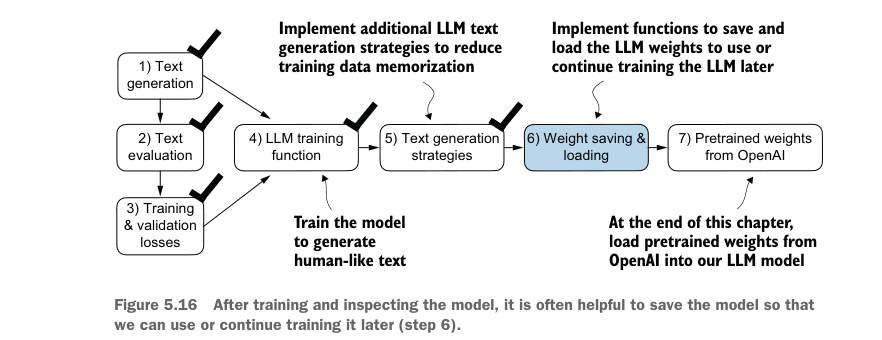
---


In [ ]:
# ==============================================================
# Saving and Loading Model Weights (Inference Checkpoint)
# ==============================================================

raw_model = trained_model.module if hasattr(trained_model, "module") else trained_model

# Save model parameters
torch.save(raw_model.state_dict(), "model.pth")
print("Model state_dict saved to model.pth")

# Load weights into a freshly initialized model instance
loaded_model = GPTModel(GPT2_CONFIG)
loaded_model.load_state_dict(torch.load("model.pth", map_location=device))
loaded_model.to(device)
loaded_model.eval()

# Verify loaded model reproduces identical generation
torch.manual_seed(123)
test_ids = generate(
    model=loaded_model,
    idx=encoded_prompt.to(device),
    max_new_tokens=15,
    context_size=GPT2_CONFIG["context_length"],
    temperature=0.0
)
print("Loaded Model Output:\n", token_ids_to_text(test_ids, tokenizer))


In [ ]:
# ==============================================================
# Saving and Resuming Full Training Checkpoint (Model + Optimizer)
# ==============================================================

# Save composite checkpoint
checkpoint_path = "model_and_optimizer.pth"
torch.save({
    "model_state_dict": raw_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}, checkpoint_path)
print(f"Full training checkpoint saved to {checkpoint_path}")

# Restore model and optimizer
checkpoint = torch.load(checkpoint_path, map_location=device)
resumed_model = GPTModel(GPT2_CONFIG)
resumed_model.load_state_dict(checkpoint["model_state_dict"])
resumed_model.to(device)

resumed_optimizer = torch.optim.AdamW(resumed_model.parameters(), lr=0.0004, weight_decay=0.1)
resumed_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

print("Successfully restored model and AdamW optimizer states!")
print("Model is ready for continuous pretraining.")


# 5.5 Chapter Summary and Key Takeaways

1. **Self-Supervised Pretraining:**
   - Pretraining on unlabeled text transforms language modeling into a supervised task by predicting the next token ($x_t \\to x_{t+1}$) using causal masking.
2. **Cross-Entropy Loss Formulation:**
   - Loss measures the negative log probability of the true next token. PyTorch's `F.cross_entropy` handles numerical stabilization and flattening across batch and sequence dimensions.
3. **Perplexity:**
   - Computed as $\\text{Perplexity} = \\exp(\\text{Loss})$. It represents the effective number of words among which the model is uncertain.
4. **Pretraining Loop & Auto Batch Sizing:**
   - Hugging Face Accelerate's `find_executable_batch_size` dynamically finds the largest safe batch size that fits in GPU VRAM without manual tuning or OOM crashes.
5. **Multi-GPU Utilization:**
   - `torch.nn.DataParallel` distributes the batch across multiple GPUs (e.g. 2× T4) for doubled training throughput.
6. **Streaming Large Corpora:**
   - Using chunk-based streaming and on-the-fly slicing allows training on 100M+ tokens from 12 GB datasets with under 500 MB RAM.
7. **Decoding Strategies:**
   - **Greedy Decoding:** Deterministic, repetitive.
   - **Temperature Scaling ($T$):** Modulates probability peakiness ($T < 1$ for confident text, $T > 1$ for diverse text).
   - **Top-$k$ Sampling:** Excludes low-probability tail tokens by masking non-top-$k$ logits with $-\\infty$.
8. **Model Checkpointing & W&B:**
   - Saving both `model.state_dict()` and `optimizer.state_dict()` guarantees smooth training resumption without gradient shocks. W&B Artifacts allow versioning checkpoints and freezing the best model.


# 5.6 Exercises

### Exercise 5.1: Analyzing Sampling Frequencies with Temperature
Using the `print_sampled_tokens` function, observe sampling frequencies when temperature is scaled to $T=0.1$, $T=1.0$, and $T=5.0$:
- **At $T=0.1$:** The word *"forward"* is chosen nearly $100\\%$ of the time, mirroring greedy decoding.
- **At $T=5.0$:** Probability flattens, causing unexpected tokens like *"pizza"* to be selected $\\approx 4\\%$ of the time.
- **Analytical Solution:** Instead of repeating sampling 1,000 times, the exact probability is obtained directly via `softmax_with_temperature(logits, T)[vocab['pizza']]`.

### Exercise 5.2: Applications of Temperature and Top-k Settings
- **Low Temperature ($T \\le 0.2$) / Low Top-k ($k \\le 10$):**
  - Coding assistants, factual Q&A, mathematical reasoning, translation, where precision and predictability are paramount.
- **Moderate Temperature ($0.7 \\le T \\le 1.0$) / Moderate Top-k ($25 \\le k \\le 50$):**
  - General conversational chat, summarization, explanation.
- **High Temperature ($T \\ge 1.2$) / Higher Top-k ($k \\ge 50$):**
  - Creative fiction, poetry, brainstorms, where novel stylistic variation is desirable.

### Exercise 5.3: Forcing Deterministic Behavior in `generate`
To force deterministic generation matching `generate_text_simple`:
- Set `temperature = 0.0`.
- Alternatively, set `top_k = 1`.

### Exercise 5.4: Resuming Training from a Saved Checkpoint
By restoring both `model.load_state_dict(checkpoint['model_state_dict'])` and `optimizer.load_state_dict(checkpoint['optimizer_state_dict'])`, we can seamlessly run `train_model_simple` for further epochs without resetting optimizer momentum.
